In [2]:
import pandas as pd
import numpy as np

# Load the sales dataset
sales = pd.read_csv("../data/raw/sales_train_validation.csv")

# Select our existing item-store combination
target = sales[
    (sales["item_id"] == "FOODS_3_090") &
    (sales["store_id"] == "CA_3")
].iloc[0]

# Extract daily sales columns
day_columns = [
    col for col in sales.columns
    if col.startswith("d_")
]

# Create the daily demand series
series = target[day_columns].astype(float).to_numpy()

print("Total observations:", len(series))
print("First 10 observations:", series[:10])
print("Last 10 observations:", series[-10:])

Total observations: 1913
First 10 observations: [108. 132. 102. 120. 106. 123. 279. 175. 186. 120.]
Last 10 observations: [129. 160. 204.  86. 100.  88.  77. 141. 139. 130.]


In [3]:
# Create a date range for the 1,913 daily observations
dates = pd.date_range(
    start="2011-01-29",
    periods=len(series),
    freq="D"
)

# Create a feature DataFrame
features = pd.DataFrame({
    "date": dates,
    "sales": series
})

# Extract calendar features
features["day_of_week"] = features["date"].dt.dayofweek
features["day_of_month"] = features["date"].dt.day
features["month"] = features["date"].dt.month
features["year"] = features["date"].dt.year
features["week_of_year"] = (
    features["date"].dt.isocalendar().week.astype(int)
)

# Weekend indicator: Monday=0, Sunday=6
features["is_weekend"] = (
    features["day_of_week"] >= 5
).astype(int)

# Display the engineered features
display(features.head(10))

,date,sales,day_of_week,day_of_month,month,year,week_of_year,is_weekend
0,2011-01-29,108.0,5,29,1,2011,4,1
1,2011-01-30,132.0,6,30,1,2011,4,1
2,2011-01-31,102.0,0,31,1,2011,5,0
3,2011-02-01,120.0,1,1,2,2011,5,0
4,2011-02-02,106.0,2,2,2,2011,5,0
5,2011-02-03,123.0,3,3,2,2011,5,0
6,2011-02-04,279.0,4,4,2,2011,5,0
7,2011-02-05,175.0,5,5,2,2011,5,1
8,2011-02-06,186.0,6,6,2,2011,5,1
9,2011-02-07,120.0,0,7,2,2011,6,0


In [4]:
print("Shape:", features.shape)
print("\nColumns:")
print(features.columns.tolist())

display(features.head(10))

Shape: (1913, 8)

Columns:
['date', 'sales', 'day_of_week', 'day_of_month', 'month', 'year', 'week_of_year', 'is_weekend']


,date,sales,day_of_week,day_of_month,month,year,week_of_year,is_weekend
0,2011-01-29,108.0,5,29,1,2011,4,1
1,2011-01-30,132.0,6,30,1,2011,4,1
2,2011-01-31,102.0,0,31,1,2011,5,0
3,2011-02-01,120.0,1,1,2,2011,5,0
4,2011-02-02,106.0,2,2,2,2011,5,0
5,2011-02-03,123.0,3,3,2,2011,5,0
6,2011-02-04,279.0,4,4,2,2011,5,0
7,2011-02-05,175.0,5,5,2,2011,5,1
8,2011-02-06,186.0,6,6,2,2011,5,1
9,2011-02-07,120.0,0,7,2,2011,6,0


In [5]:

# Lag features: previous sales values
features["lag_1"] = features["sales"].shift(1)
features["lag_7"] = features["sales"].shift(7)
features["lag_14"] = features["sales"].shift(14)
features["lag_28"] = features["sales"].shift(28)

# Rolling averages using only past observations
features["rolling_mean_7"] = (
    features["sales"].shift(1).rolling(window=7).mean()
)

features["rolling_mean_28"] = (
    features["sales"].shift(1).rolling(window=28).mean()
)

# Rolling standard deviation: recent demand variability
features["rolling_std_7"] = (
    features["sales"].shift(1).rolling(window=7).std()
)

# Inspect the newly created features
print("Dataset shape:", features.shape)
print("\nMissing values in engineered columns:")
print(features.iloc[:, 8:].isna().sum())

display(features.tail(10))


Dataset shape: (1913, 15)

Missing values in engineered columns:
lag_1               1
lag_7               7
lag_14             14
lag_28             28
rolling_mean_7      7
rolling_mean_28    28
rolling_std_7       7
dtype: int64


,date,sales,day_of_week,day_of_month,month,year,week_of_year,is_weekend,lag_1,lag_7,lag_14,lag_28,rolling_mean_7,rolling_mean_28,rolling_std_7
1903,2016-04-15,129.0,4,15,4,2016,15,0,90.0,107.0,156.0,98.0,108.571429,111.142857,26.644932
1904,2016-04-16,160.0,5,16,4,2016,15,1,129.0,160.0,133.0,182.0,111.714286,112.250000,27.705079
1905,2016-04-17,204.0,6,17,4,2016,15,1,160.0,124.0,114.0,109.0,111.714286,111.464286,27.705079
1906,2016-04-18,86.0,0,18,4,2016,16,0,204.0,107.0,80.0,63.0,123.142857,114.857143,44.827181
1907,2016-04-19,100.0,1,19,4,2016,16,0,86.0,84.0,75.0,80.0,120.142857,115.678571,46.749077
1908,2016-04-20,88.0,2,20,4,2016,16,0,100.0,88.0,113.0,90.0,122.428571,116.392857,45.047594
1909,2016-04-21,77.0,3,21,4,2016,16,0,88.0,90.0,81.0,71.0,122.428571,116.321429,45.047594
1910,2016-04-22,141.0,4,22,4,2016,16,0,77.0,129.0,107.0,153.0,120.571429,116.535714,46.839645
1911,2016-04-23,139.0,5,23,4,2016,16,1,141.0,160.0,160.0,218.0,122.285714,116.107143,47.415589
1912,2016-04-24,130.0,6,24,4,2016,16,1,139.0,204.0,124.0,212.0,119.285714,113.285714,45.246415


In [6]:

# Check missing values before cleaning
print("Missing values before cleaning:")
print(features.isnull().sum())

# Remove rows without sufficient historical data
features_clean = features.dropna().reset_index(drop=True)

print("\nShape before cleaning:", features.shape)
print("Shape after cleaning:", features_clean.shape)

# Verify the cleaned dataset
print("\nMissing values after cleaning:")
print(features_clean.isnull().sum().sum())

display(features_clean.head())


Missing values before cleaning:
date                0
sales               0
day_of_week         0
day_of_month        0
month               0
year                0
week_of_year        0
is_weekend          0
lag_1               1
lag_7               7
lag_14             14
lag_28             28
rolling_mean_7      7
rolling_mean_28    28
rolling_std_7       7
dtype: int64

Shape before cleaning: (1913, 15)
Shape after cleaning: (1885, 15)

Missing values after cleaning:
0


,date,sales,day_of_week,day_of_month,month,year,week_of_year,is_weekend,lag_1,lag_7,lag_14,lag_28,rolling_mean_7,rolling_mean_28,rolling_std_7
0,2011-02-26,0.0,5,26,2,2011,8,1,0.0,0.0,0.0,108.0,0.0,51.821429,0.0
1,2011-02-27,0.0,6,27,2,2011,8,1,0.0,0.0,0.0,132.0,0.0,47.964286,0.0
2,2011-02-28,0.0,0,28,2,2011,9,0,0.0,0.0,0.0,102.0,0.0,43.250000,0.0
3,2011-03-01,0.0,1,1,3,2011,9,0,0.0,0.0,0.0,120.0,0.0,39.607143,0.0
4,2011-03-02,0.0,2,2,3,2011,9,0,0.0,0.0,0.0,106.0,0.0,35.321429,0.0


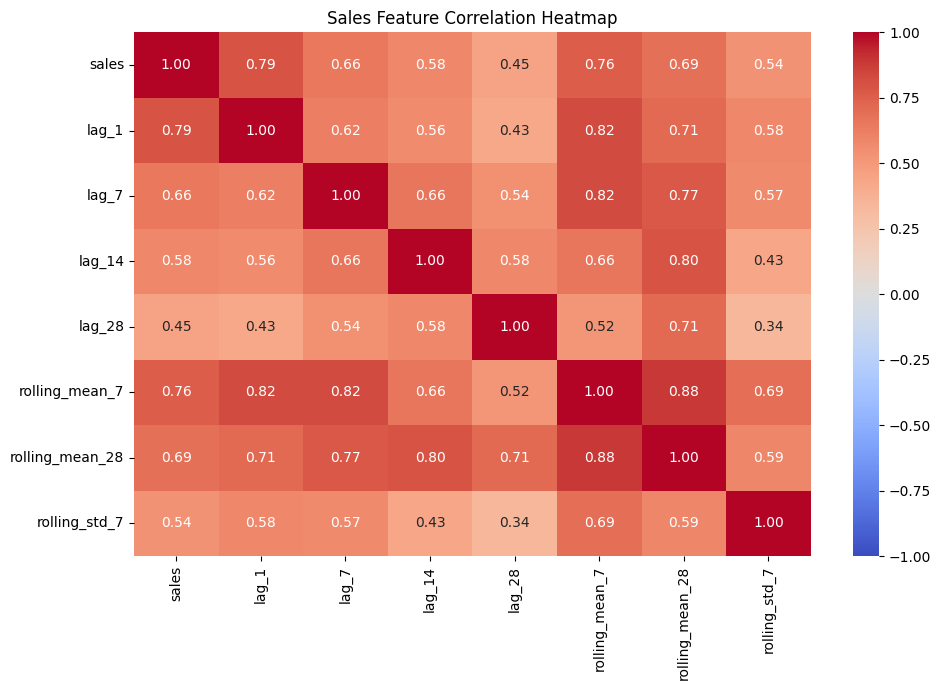

In [7]:

import matplotlib.pyplot as plt
import seaborn as sns

# Select numerical features for correlation analysis
correlation_features = [
    "sales",
    "lag_1",
    "lag_7",
    "lag_14",
    "lag_28",
    "rolling_mean_7",
    "rolling_mean_28",
    "rolling_std_7"
]

correlation_matrix = features_clean[
    correlation_features
].corr()

# Plot the correlation heatmap
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Sales Feature Correlation Heatmap")
plt.tight_layout()
plt.show()


In [8]:

# Save the cleaned feature dataset
output_path = "../data/processed/retail_demand_features.csv"

features_clean.to_csv(output_path, index=False)

print("Feature dataset saved successfully!")
print("File:", output_path)
print("Shape:", features_clean.shape)


Feature dataset saved successfully!
File: ../data/processed/retail_demand_features.csv
Shape: (1885, 15)


In [1]:

import pandas as pd
import numpy as np

sales = pd.read_csv("../data/raw/sales_train_validation.csv")

item_id = "FOODS_3_090"
store_id = "CA_3"

target = sales.loc[
    (sales["item_id"] == item_id) &
    (sales["store_id"] == store_id)
]

print("Matching rows:", len(target))

if len(target) == 1:
    target = target.iloc[0]

    day_columns = [
        col for col in sales.columns
        if col.startswith("d_")
    ]

    series = target[day_columns].astype(float).to_numpy()

    dates = pd.date_range(
        start="2011-01-29",
        periods=len(series),
        freq="D"
    )

    daily = pd.DataFrame({
        "date": dates,
        "sales": series
    })

    print("\nDataset shape:", daily.shape)
    print("First date:", daily["date"].min())
    print("Last date:", daily["date"].max())
    print("Zero-sales days:", (daily["sales"] == 0).sum())
    print("Positive-sales days:", (daily["sales"] > 0).sum())

    print("\nFirst positive-sales date:")
    print(daily.loc[daily["sales"] > 0].head(1))

    print("\nSales around September 2011:")
    display(
        daily.loc[
            daily["date"].between(
                "2011-09-19", "2011-09-30"
            )
        ]
    )

else:
    print("Expected exactly one matching row.")


Matching rows: 1

Dataset shape: (1913, 2)
First date: 2011-01-29 00:00:00
Last date: 2016-04-24 00:00:00
Zero-sales days: 359
Positive-sales days: 1554

First positive-sales date:
        date  sales
0 2011-01-29  108.0

Sales around September 2011:


,date,sales
233,2011-09-19,0.0
234,2011-09-20,0.0
235,2011-09-21,0.0
236,2011-09-22,0.0
237,2011-09-23,0.0
238,2011-09-24,0.0
239,2011-09-25,420.0
240,2011-09-26,280.0
241,2011-09-27,273.0
242,2011-09-28,254.0


In [2]:

# Identify consecutive zero-sales periods in the original series

sales_check = daily.copy().sort_values("date").reset_index(drop=True)

sales_check["is_zero"] = sales_check["sales"].eq(0)

# Assign a new group whenever the zero/non-zero status changes
sales_check["group"] = (
    sales_check["is_zero"] != sales_check["is_zero"].shift()
).cumsum()

zero_periods = (
    sales_check[sales_check["is_zero"]]
    .groupby("group")
    .agg(
        start_date=("date", "min"),
        end_date=("date", "max"),
        days=("date", "size")
    )
    .sort_values("days", ascending=False)
    .reset_index(drop=True)
)

print("Number of consecutive zero-sales periods:", len(zero_periods))
print("\nLongest zero-sales periods:")
display(zero_periods.head(15))

print("\nZero-sales duration summary:")
print(zero_periods["days"].describe())

print("\nPeriods lasting at least 30 days:")
display(zero_periods[zero_periods["days"] >= 30])


Number of consecutive zero-sales periods: 63

Longest zero-sales periods:


,start_date,end_date,days
0,2011-02-08,2011-09-24,229
1,2015-12-29,2016-01-06,9
2,2015-03-06,2015-03-11,6
3,2014-12-01,2014-12-05,5
4,2014-12-31,2015-01-04,5
5,2013-12-21,2013-12-25,5
6,2014-01-07,2014-01-10,4
7,2014-12-22,2014-12-25,4
8,2014-02-09,2014-02-12,4
9,2014-06-07,2014-06-10,4



Zero-sales duration summary:
count     63.000000
mean       5.698413
std       28.628677
min        1.000000
25%        1.000000
50%        2.000000
75%        3.000000
max      229.000000
Name: days, dtype: float64

Periods lasting at least 30 days:


,start_date,end_date,days
0,2011-02-08,2011-09-24,229


In [3]:

# Investigate the longest zero-sales period

longest = zero_periods.iloc[0]

start_date = pd.to_datetime(longest["start_date"])
end_date = pd.to_datetime(longest["end_date"])

print("Longest zero-sales period:")
print("Start:", start_date)
print("End:", end_date)
print("Days:", longest["days"])

print("\nSales immediately before, during, and after the period:")

window = daily[
    (daily["date"] >= start_date - pd.Timedelta(days=7))
    & (daily["date"] <= end_date + pd.Timedelta(days=7))
].copy()

display(window)

print("\nPositive sales before the period:")
display(
    daily[
        (daily["date"] < start_date)
        & (daily["sales"] > 0)
    ].tail(10)
)

print("\nPositive sales after the period:")
display(
    daily[
        (daily["date"] > end_date)
        & (daily["sales"] > 0)
    ].head(10)
)


Longest zero-sales period:
Start: 2011-02-08 00:00:00
End: 2011-09-24 00:00:00
Days: 229

Sales immediately before, during, and after the period:


,date,sales
3,2011-02-01,120.0
4,2011-02-02,106.0
5,2011-02-03,123.0
6,2011-02-04,279.0
7,2011-02-05,175.0
...,...,...
241,2011-09-27,273.0
242,2011-09-28,254.0
243,2011-09-29,240.0
244,2011-09-30,336.0



Positive sales before the period:


,date,sales
0,2011-01-29,108.0
1,2011-01-30,132.0
2,2011-01-31,102.0
3,2011-02-01,120.0
4,2011-02-02,106.0
5,2011-02-03,123.0
6,2011-02-04,279.0
7,2011-02-05,175.0
8,2011-02-06,186.0
9,2011-02-07,120.0



Positive sales after the period:


,date,sales
239,2011-09-25,420.0
240,2011-09-26,280.0
241,2011-09-27,273.0
242,2011-09-28,254.0
243,2011-09-29,240.0
244,2011-09-30,336.0
245,2011-10-01,478.0
246,2011-10-02,359.0
247,2011-10-03,234.0
248,2011-10-04,180.0


In [4]:

# Verify the original source data for this item-store combination

import pandas as pd

sales = pd.read_csv("../data/raw/sales_train_validation.csv")

item_id = "FOODS_3_090"
store_id = "CA_3"

item_store = sales[
    (sales["item_id"] == item_id)
    & (sales["store_id"] == store_id)
]

day_columns = sorted(
    [col for col in sales.columns if col.startswith("d_")],
    key=lambda col: int(col.split("_")[1])
)

print("Matching rows:", len(item_store))
print("Daily columns:", len(day_columns))

if len(item_store) == 1:
    values = item_store.iloc[0][day_columns].astype(float)

    print("Total zero-sales days:", int((values == 0).sum()))
    print("Total positive-sales days:", int((values > 0).sum()))

    # Inspect the original daily values around the transition
    check_days = [
        f"d_{i}" for i in range(1, len(day_columns) + 1)
        if 180 <= i <= 250
    ]

    display(
        pd.DataFrame({
            "day": check_days,
            "sales": values[check_days].values
        })
    )
else:
    print("Unexpected number of matching item-store rows.")


Matching rows: 1
Daily columns: 1913
Total zero-sales days: 359
Total positive-sales days: 1554


,day,sales
0,d_180,0.0
1,d_181,0.0
2,d_182,0.0
3,d_183,0.0
4,d_184,0.0
...,...,...
66,d_246,478.0
67,d_247,359.0
68,d_248,234.0
69,d_249,180.0


In [5]:

import pandas as pd

# Inspect the processed feature dataset
processed = pd.read_csv(
    "../data/processed/retail_demand_features.csv"
)

print("Processed dataset shape:", processed.shape)
print("Zero-sales rows:", int((processed["sales"] == 0).sum()))
print("Positive-sales rows:", int((processed["sales"] > 0).sum()))
print("Missing sales values:", int(processed["sales"].isna().sum()))

print("\nDate range:")
print("Start:", processed["date"].min())
print("End:", processed["date"].max())

print("\nZero-sales periods of at least 30 days:")
processed["date"] = pd.to_datetime(processed["date"])
processed = processed.sort_values("date").reset_index(drop=True)

zero_mask = processed["sales"].eq(0)
group_id = (~zero_mask).cumsum()

long_runs = (
    processed[zero_mask]
    .groupby(group_id[zero_mask])
    .agg(
        start_date=("date", "min"),
        end_date=("date", "max"),
        days=("date", "size")
    )
)

display(long_runs[long_runs["days"] >= 30])


Processed dataset shape: (1885, 15)
Zero-sales rows: 341
Positive-sales rows: 1544
Missing sales values: 0

Date range:
Start: 2011-02-26
End: 2016-04-24

Zero-sales periods of at least 30 days:


,start_date,end_date,days
sales,,,
0,2011-02-26,2011-09-24,211
